# Bitcoin OTC: network structure and model comparison

This notebook explains the reproducible results produced by `scripts/structural_analysis.py`. Run `python scripts/reproduce.py` from the project root after downloading the SNAP file. This notebook combines small executable examples, calculations directly from source rows, and results in `outputs/structure/` and `outputs/sensitivity/`.

## 1. What is the network?

A user is a node. A rating from user $u$ to user $v$ is a directed, signed edge $u\to v$. The primary analysis keeps ratings $>0$ and retains all observed users, including users with no positive ratings. Its directed **in-degree** counts distinct positive raters received by a user. The comparison models below use undirected networks. We connect two users with one undirected link if either direction has a positive rating. A reciprocal pair becomes one link. We report the number of collapsed reciprocal pairs explicitly. This undirected network of positive ratings discards direction and rating strength; it must not be interpreted as the original trust network.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'outputs' / 'structure'
assert (OUT / 'metadata.json').exists(), 'Run python scripts/structural_analysis.py from the project root first.'
meta = json.loads((OUT / 'metadata.json').read_text())
metrics = pd.read_csv(OUT / 'network_metrics.csv')
centrality = pd.read_csv(OUT / 'directed_centrality.csv')
communities = pd.read_csv(OUT / 'communities.csv')
display(pd.Series(meta, name='value'))

source_rows                                                                              35592
source_sha256                                6424ac981dad3a019f697fc1b9fcd85c19d8d9f0397977...
positive_directed_edges                                                                  32029
projection_edges                                                                         18591
reciprocal_positive_pairs_collapsed                                                      13438
ba_links_per_new_node                                                                        3
ba_edge_count_mismatch_fraction                                                      -0.051477
model_replicates                                                                            10
betweenness_source_sample                                                                   64
path_source_sample                                                                          32
louvain_community_count                           

## 2. Structural measures

Following the class notation, a simple undirected graph has $N$ nodes and $L$ links. Mean degree is $2L/N$ and density is $2L/[N(N-1)]$. **Transitivity** is three times the number of triangles divided by the number of connected triples; it is the global clustering measure used here. The graph is disconnected, so a single whole-network mean path length or diameter is undefined. We calculate an exact diameter on the largest connected component. Mean path length is an approximation from a fixed sample of source nodes on that component; it is labelled as such. Notebook 05 compares it with the exact value. Each positive link has distance **one hop**; rating magnitude is retained as an attribute but is not used as a distance. Directed betweenness also uses unweighted positive paths. The full directed network remains available for in/out-degree and approximate betweenness centrality.

In [2]:
observed = metrics.loc[metrics.network == 'observed'].iloc[0]
display(observed.to_frame('observed'))
print('Top positive in-degree users (anonymous node IDs):')
display(centrality.head(10))
print('Largest observed communities:')
display(communities.groupby('community').size().sort_values(ascending=False).head(10).rename('nodes'))

,observed
network,observed
nodes,5881
edges,18591
mean_degree,6.322394
degree_p95,23.0
max_degree,788
density,0.001075
transitivity,0.05702
components,317
largest_component_nodes,5551


Top positive in-degree users (anonymous node IDs):


,node,positive_in_degree,positive_out_degree,betweenness_approx
0,35,535,753,0.148332
1,2642,411,397,0.072534
2,1810,270,244,0.023500
3,2028,234,267,0.037843
4,1,226,206,0.046174
5,905,226,223,0.038869
6,7,216,225,0.062764
7,4172,211,190,0.037416
8,4197,203,199,0.016400
9,13,190,193,0.036650


Largest observed communities:


community
50     1096
5      1029
21      867
37      758
15      631
71      581
299     218
91       83
33       75
9        60
Name: nodes, dtype: int64

### Work the formulas on a small graph

This is an **invented five-user teaching example**. Its values are not Bitcoin OTC results. A positive score creates an arrow from rater to recipient. The negative rating from D to E is excluded from the directed network of positive ratings, but E remains a node. The two arrows between A and B become one undirected link in the undirected network.

In [3]:
import networkx as nx

example_ratings = pd.DataFrame([
    ('A', 'B', 4), ('B', 'A', 5), ('B', 'C', 3),
    ('C', 'A', 2), ('C', 'D', 1), ('D', 'E', -5),
], columns=['source', 'target', 'rating'])

example_directed_network = nx.DiGraph()
example_directed_network.add_nodes_from(sorted(set(example_ratings.source) | set(example_ratings.target)))
for row in example_ratings.itertuples(index=False):
    if row.rating > 0:
        example_directed_network.add_edge(row.source, row.target, rating=row.rating)
example_undirected_network = example_directed_network.to_undirected()

display(example_ratings)
print('Positive arrows:', sorted(example_directed_network.edges()))
print('Undirected links:', sorted(example_undirected_network.edges()))
display(pd.DataFrame({
    'positive_in_degree': dict(example_directed_network.in_degree()),
    'positive_out_degree': dict(example_directed_network.out_degree()),
    'undirected_degree': dict(example_undirected_network.degree()),
}))

,source,target,rating
0,A,B,4
1,B,A,5
2,B,C,3
3,C,A,2
4,C,D,1
5,D,E,-5


Positive arrows: [('A', 'B'), ('B', 'A'), ('B', 'C'), ('C', 'A'), ('C', 'D')]
Undirected links: [('A', 'B'), ('A', 'C'), ('B', 'C'), ('C', 'D')]


,positive_in_degree,positive_out_degree,undirected_degree
A,2,1,2
B,1,2,2
C,1,2,3
D,1,0,1
E,0,0,0


There are $N=5$ users and $L=4$ undirected links. Each link contributes to the degree of both endpoints, so the mean degree is $2L/N=8/5=1.6$. The possible number of undirected pairs is $N(N-1)/2=10$, so the density is $4/10=0.4$.

A **connected triple** is a pair of links sharing a middle node. A node of degree $k$ centers $k(k-1)/2$ such triples. This graph has one triangle, which closes three of its five connected triples. Its global transitivity is therefore $3\times1/5=0.6$. The local clustering coefficient from class measures closure separately around each node; averaging those local values gives a different number here.

In [4]:
N = example_undirected_network.number_of_nodes()
L = example_undirected_network.number_of_edges()
mean_degree = 2 * L / N
density = 2 * L / (N * (N - 1))
triangles = sum(nx.triangles(example_undirected_network).values()) // 3
connected_triples = sum(k * (k - 1) // 2 for _, k in example_undirected_network.degree())
transitivity = 3 * triangles / connected_triples

print('Mean degree =', mean_degree)
print('Density =', density)
print('Triangles =', triangles, '; connected triples =', connected_triples)
print('Global transitivity =', transitivity)
print('Mean local clustering (including isolates) =', nx.average_clustering(example_undirected_network))
print('Shortest undirected path D to A =', nx.shortest_path(example_undirected_network, 'D', 'A'))
print('Its length =', nx.shortest_path_length(example_undirected_network, 'D', 'A'), 'hops')
print('Connected components =', list(nx.connected_components(example_undirected_network)))

assert mean_degree == sum(dict(example_undirected_network.degree()).values()) / N
assert density == nx.density(example_undirected_network)
assert transitivity == nx.transitivity(example_undirected_network)

Mean degree = 1.6
Density = 0.4
Triangles = 1 ; connected triples = 5
Global transitivity = 0.6
Mean local clustering (including isolates) = 0.4666666666666667
Shortest undirected path D to A = ['D', 'C', 'A']
Its length = 2 hops
Connected components = [{'C', 'A', 'B', 'D'}, {'E'}]


E is isolated after positive filtering, so there is no finite path between E and the other users. That is why the full analysis reports paths on the **largest connected component**. D–C–A has two hops in the undirected network; the scores do not change those hop distances. In the directed network of positive ratings, D has no outgoing arrow, so that directed path does not exist.

## 3. Two theoretical baselines

**ER $G(N,L)$:** draws exactly the observed number of undirected links uniformly among node pairs. It controls for node and edge counts but does not model social rating choices.

**BA:** adds each new node with `ba_links_per_new_node` preferentially chosen existing neighbors. The model's integer parameter cannot exactly match the observed link count here: $L_{BA}=17{,}634$ versus $L_{obs}=18{,}591$ (5.15% fewer). The difference is disclosed; we do not silently add random links to the BA graph. BA is undirected and assumes every new link comes from a new node, unlike this rating network. Each baseline is generated with ten fixed seeds. The reported spread is variation across simulations, not confidence intervals for the observed network.

edges      max_degree          transitivity          \
             mean  std       mean      std         mean     std   
family                                                            
BA        17634.0  0.0      231.0  24.2716       0.0042  0.0003   
ER        18591.0  0.0       17.1   1.1972       0.0011  0.0002   
observed  18591.0  NaN      788.0      NaN       0.0570     NaN   

         largest_component_share         sampled_mean_path_lcc          
                            mean     std                  mean     std  
family                                                                  
BA                        1.0000  0.0000                4.0821  0.0702  
ER                        0.9982  0.0006                4.9132  0.0539  
observed                  0.9439     NaN                3.5594     NaN

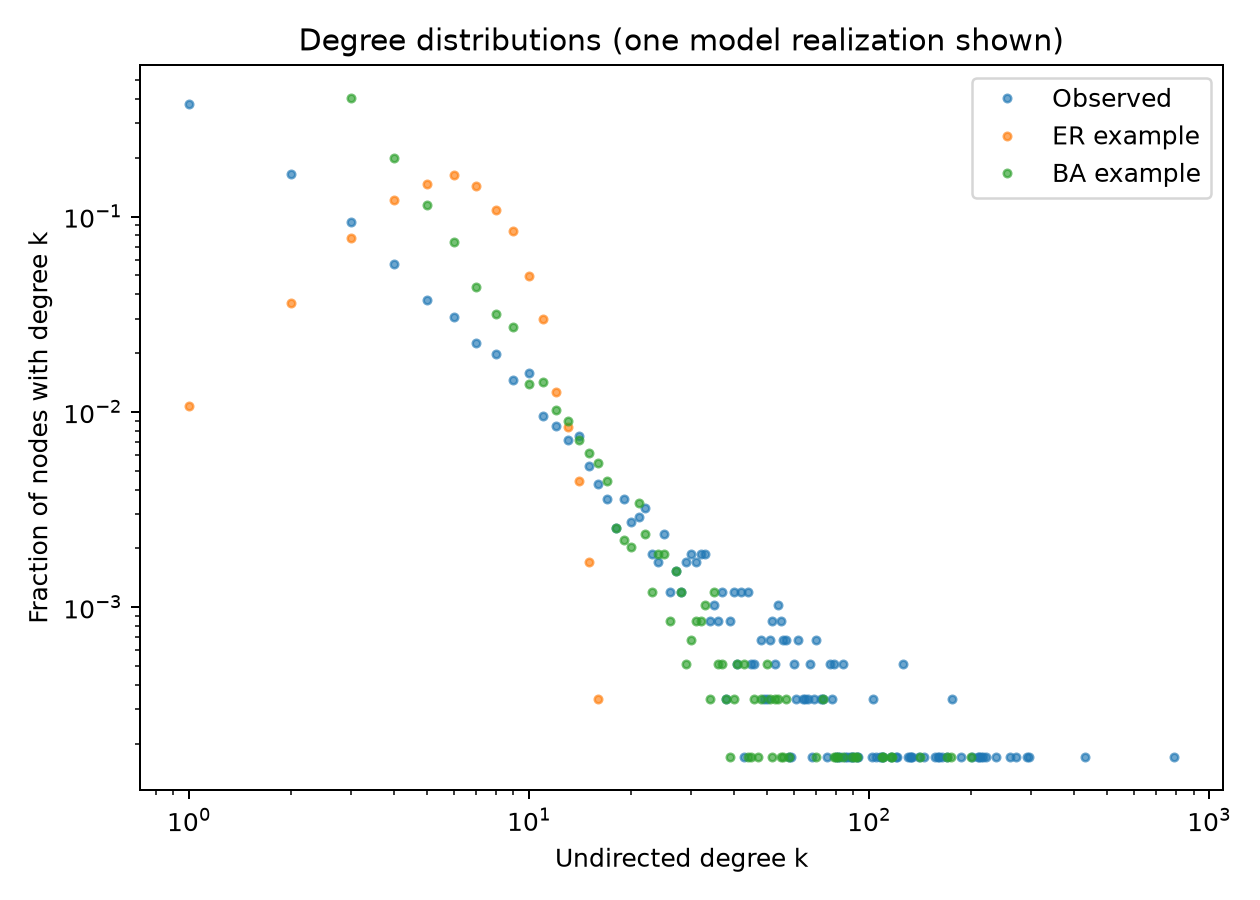

In [5]:
metrics['family'] = metrics.network.str.split('_').str[0]
columns = ['edges', 'max_degree', 'transitivity', 'largest_component_share', 'sampled_mean_path_lcc']
comparison = metrics.groupby('family')[columns].agg(['mean', 'std']).round(4)
display(comparison)
display(Image(filename=str(OUT / 'degree_distributions.png')))

## 4. Communities and interpretation

Louvain optimizes modularity on the **undirected network of positive ratings**. Its partitions are algorithmic groups, not verified trading communities. The reported modularity does not by itself establish that the partition is unique or substantively meaningful. Notebook 05 reruns Louvain across seeds. Direction and negative ratings are excluded from this analysis.

The observed degree tail and transitivity can be compared with ER and BA. A resemblance to BA does **not** demonstrate preferential attachment; that mechanism would require a separate event-level temporal test. The focused investigation in notebooks 03 and 04 measures cumulative rating concentration and compares recipients with eligible users at each event.

Retaining every observed user also retains users with no positive links. Each isolated user forms a singleton group. The counts below distinguish those isolated users from groups containing two or more users; the total group count alone can exaggerate the amount of community structure.

In [6]:
community_sizes = communities.groupby('community').size()
positive_isolates = ((centrality.positive_in_degree == 0) & (centrality.positive_out_degree == 0)).sum()
print('All Louvain groups:', meta['louvain_community_count'])
print('Singleton groups:', int((community_sizes == 1).sum()))
print('Groups with at least two users:', int((community_sizes >= 2).sum()))
print('Users with no positive links:', int(positive_isolates))
print('Modularity:', round(meta['louvain_modularity'], 4))
print('Exact diameter of largest observed component:', meta['largest_observed_component_diameter_exact'])
print('Positive directed edges collapsed by projection:', meta['reciprocal_positive_pairs_collapsed'])

All Louvain groups: 341
Singleton groups: 308
Groups with at least two users: 33
Users with no positive links: 308
Modularity: 0.5042
Exact diameter of largest observed component: 14
Positive directed edges collapsed by projection: 13438


### Describe a real group through its links

The profiles below describe the five largest computed Louvain groups. A link inside a group has **two endpoints in that group**; a link crossing its boundary has one. Therefore the fraction of a group's link endpoints whose other endpoint is in the same group is

$$\frac{2\times\text{internal links}}{2\times\text{internal links}+\text{boundary links}}.$$

The next cell reconstructs the undirected network of positive ratings from the source and works this calculation for the largest group. This describes the partition; Louvain already favors internal connectivity, so a high internal fraction is not an independent validation of the groups. Anonymous account IDs do not reveal what kind of trading or social groups these are.

In [7]:
profiles = pd.read_csv(ROOT / 'outputs' / 'sensitivity' / 'community_profiles.csv')
display(profiles[['group_rank_by_size', 'users', 'internal_links', 'boundary_links',
                  'within_group_endpoint_fraction']].round(4))

source_ratings = pd.read_csv(
    ROOT / 'data' / 'soc-sign-bitcoinotc.csv.gz',
    header=None, names=['source', 'target', 'rating', 'time'],
)
positive_rows = source_ratings[source_ratings.rating > 0]
positive_undirected_network = nx.from_pandas_edgelist(positive_rows, 'source', 'target')
positive_undirected_network.add_nodes_from(centrality.node)  # retain users with no positive links
largest_group = community_sizes.idxmax()
members = set(communities.loc[communities.community == largest_group, 'node'])
internal_links = positive_undirected_network.subgraph(members).number_of_edges()
boundary_links = sum((u in members) != (v in members) for u, v in positive_undirected_network.edges())
within_fraction = 2 * internal_links / (2 * internal_links + boundary_links)

print('Largest group:', len(members), 'users')
print('Internal links:', internal_links, '; boundary links:', boundary_links)
print('Internal endpoint fraction:', round(within_fraction, 4))
saved_fraction = profiles.set_index('louvain_group_id').loc[largest_group, 'within_group_endpoint_fraction']
assert abs(within_fraction - saved_fraction) < 1e-12

,group_rank_by_size,users,internal_links,boundary_links,within_group_endpoint_fraction
0,1,1096,2825,2610,0.6840
1,2,1029,2506,1658,0.7514
2,3,867,2827,3304,0.6312
3,4,758,1364,2161,0.5580
4,5,631,769,858,0.6419


Largest group: 1096 users
Internal links: 2825 ; boundary links: 2610
Internal endpoint fraction: 0.684


## Sources for the methods

- [SNAP Bitcoin OTC dataset and required dataset citation](https://snap.stanford.edu/data/soc-sign-bitcoinotc.html)
- [Erdős and Rényi, *On Random Graphs I* (1959)](https://publi.math.unideb.hu/paper/2769)
- [Barabási and Albert, *Emergence of Scaling in Random Networks* (1999)](https://doi.org/10.1126/science.286.5439.509)
- [Blondel et al., *Fast unfolding of communities in large networks* (2008)](https://doi.org/10.1088/1742-5468/2008/10/P10008)
- [NetworkX citation and documentation](https://networkx.org/documentation/stable/)

These references support the methods used in this analysis.